# 3-fish recording: accuracy of four pipelines, all EODs vs the better list of good frames

% of EODs assigned to fish 0 (the only emitter), from `results/eod_ground_truth_3fish/conductivities/eod_assignments.csv`:
- **numerical, sink at tail tip** and **numerical, sink 5% from tail tip**: my numerical field model, BEM conductivities (interior 100 × water, skin 0.05 × water over
  0.005 cm), sign fixed (warm colours);
- **analytic, SLEAP midline** (spline through the SLEAP keypoints) and **analytic, mask midline** (my mask midline): Denis'
  analytic model, his latest run (cold colours).

Two sets of EODs: all 19,796, and the 6,751 in `good_frames_better_list.csv` (common good frames, every fish's mask ≥ 0.8 × its
median length). EODs without a pick (no mask or midline) count as wrong. Distance = smallest mask-edge distance from fish 0 to the
other fish (`gap_cm`; 28 EODs without a fish 0 mask have none and are left out of the distance plot only). Error bars: 95% Wilson
intervals (left out of the better-list distance panel, where they overlap).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

OUT = 'results/eod_ground_truth_3fish/conductivities'
EMITTER = 0
PIPES = {   # label: (column of eod_assignments.csv, colour, marker, marker fill)
    'numerical, sink at tail tip': ('fish | BEM σ (interior 100, skin 0.05, 0.005 cm), sink at tail tip', '#C8361E', 'o', 'filled'),
    'numerical, sink 5% from tail tip': ('fish | BEM σ (interior 100, skin 0.05, 0.005 cm), sink 5% from tail tip', '#F08A24', 'o', 'open'),
    'analytic, SLEAP midline': ("fish | Denis' pipeline (latest run)", '#1F5FBF', 'D', 'filled'),
    'analytic, mask midline': ("fish | Denis' pipeline with my mask midline", '#17A0B0', 'D', 'open'),
}
A = pd.read_csv(f'{OUT}/eod_assignments.csv', index_col='row')
better = A.Frame.isin(pd.read_csv('results/eod_ground_truth_3fish/good_frames_better_list.csv').frame).to_numpy()
SETS = {'all EODs': np.ones(len(A), bool), 'better list of good frames': better}
assert better.sum() == 6751

def wilson(k, n, z=1.96):
    '''95% Wilson interval of k successes in n trials, in %.'''
    p = k / n; c = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n); hw = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (c - hw), 100 * (c + hw)

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'grid.linewidth': 0.8, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b', 'xtick.color': '#5a5a55',
                     'ytick.color': '#5a5a55'})

## % correct against the distance to the nearest fish

10 bins with equal numbers of EODs per panel; points at the bin median distance.

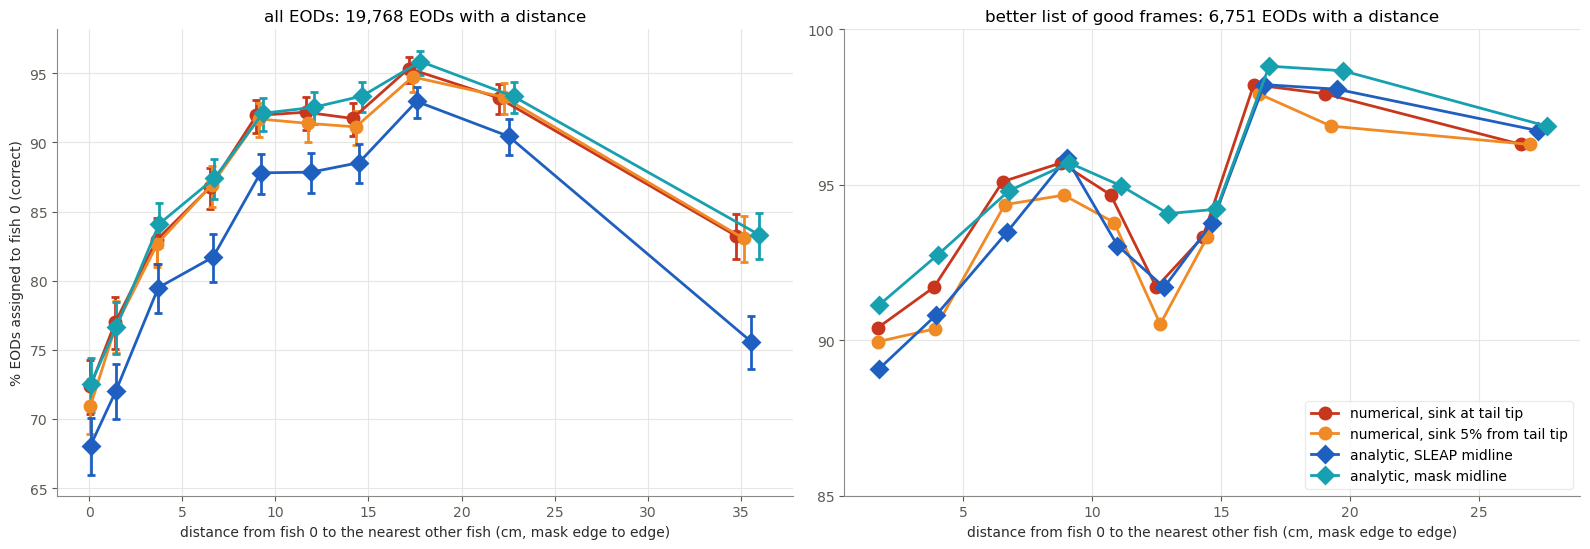

all EODs


,"numerical, sink at tail tip","numerical, sink 5% from tail tip","analytic, SLEAP midline","analytic, mask midline"
median distance (cm),,,,
0.1,72.4,70.9,68.1,72.5
1.4,77.0,76.7,72.0,76.6
3.7,82.9,82.7,79.5,84.1
6.6,86.8,86.9,81.7,87.4
9.1,91.9,91.7,87.8,92.1
11.8,92.2,91.4,87.8,92.5
14.4,91.7,91.1,88.5,93.4
17.5,95.3,94.7,93.0,95.9
22.4,93.2,93.3,90.4,93.3


better list of good frames


,"numerical, sink at tail tip","numerical, sink 5% from tail tip","analytic, SLEAP midline","analytic, mask midline"
median distance (cm),,,,
1.7,90.4,90.0,89.1,91.1
3.9,91.7,90.4,90.8,92.7
6.6,95.1,94.4,93.5,94.8
8.9,95.7,94.7,95.9,95.7
10.9,94.7,93.8,93.0,95.0
12.7,91.7,90.5,91.7,94.1
14.5,93.3,93.3,93.8,94.2
16.6,98.2,97.9,98.2,98.8
19.4,97.9,96.9,98.1,98.7


In [2]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.6))
tables = {}
for a, (s, m) in zip(axs, SETS.items()):
    sub = A[m & A.gap_cm.notna().to_numpy()]
    gr = sub.groupby(pd.qcut(sub.gap_cm, 10), observed=True); x = gr.gap_cm.median().to_numpy(); t = {}
    for j, (nm, (col, c, mk, ls)) in enumerate(PIPES.items()):
        k = gr[col].apply(lambda v: (v == EMITTER).sum()).to_numpy(); n = gr.size().to_numpy(); pct = 100 * k / n; lo, hi = wilson(k, n)
        err = None if s == 'better list of good frames' else [pct - lo, hi - pct]   # no error bars on the good-frames panel
        a.errorbar(x * (1 + 0.012 * (j - 1.5)), pct, yerr=err, color=c, marker=mk, ms=8, ls='-', lw=2, capsize=3, mfc=c, mew=2, label=nm)
        t[nm] = pct
    tables[s] = pd.DataFrame(t, index=pd.Index(x.round(1), name='median distance (cm)')).round(1)
    a.set(title=f'{s}: {len(sub):,} EODs with a distance', xlabel='distance from fish 0 to the nearest other fish (cm, mask edge to edge)')
axs[0].set_ylabel('% EODs assigned to fish 0 (correct)'); axs[1].set(ylim=(85, 100), yticks=np.arange(85, 101, 5))
axs[1].legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#e6e6e3', fontsize=10)
plt.tight_layout(); fig.savefig(f'{OUT}/figures/accuracy_vs_distance_4pipelines.png', dpi=130); plt.show()
for s, t in tables.items(): print(s); display(t)

## Overall % correct

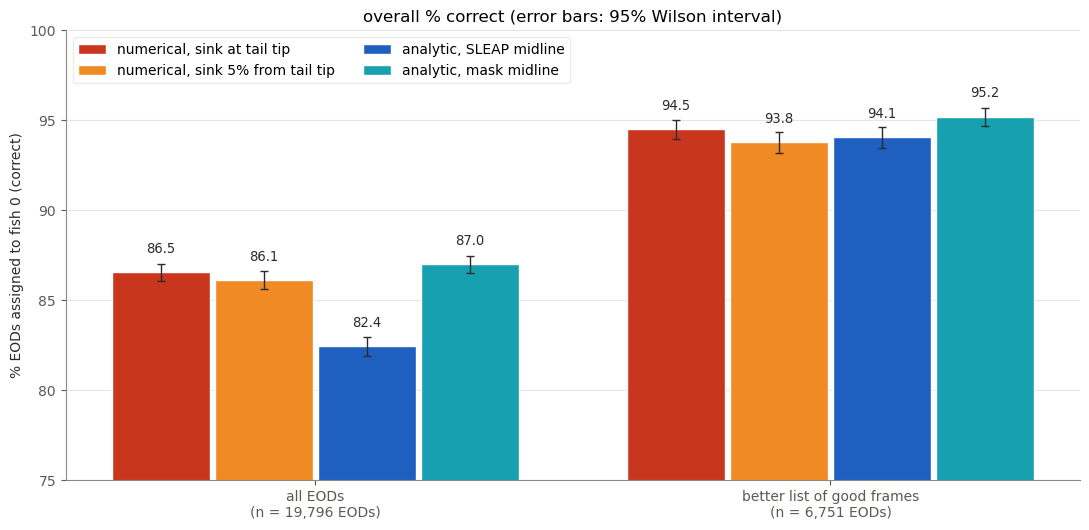

% correct  \
EODs                       pipeline                                      
all EODs                   numerical, sink at tail tip           86.55   
                           numerical, sink 5% from tail tip      86.12   
                           analytic, SLEAP midline               82.44   
                           analytic, mask midline                86.99   
better list of good frames numerical, sink at tail tip           94.50   
                           numerical, sink 5% from tail tip      93.81   
                           analytic, SLEAP midline               94.07   
                           analytic, mask midline                95.20   

                                                             95% CI low  \
EODs                       pipeline                                       
all EODs                   numerical, sink at tail tip            86.07   
                           numerical, sink 5% from tail tip       85.63   
                           analytic, SLEAP midline                81.90   
                           analytic, mask midline                 86.51   
better list of good frames numerical, sink at tail tip            93.94   
                           numerical, sink 5% from tail tip       93.21   
                           analytic, SLEAP midline                93.49   
                           analytic, mask midline                 94.66   

                                                             95% CI high  \
EODs                       pipeline                                        
all EODs                   numerical, sink at tail tip             87.02   
                           numerical, sink 5% from tail tip        86.60   
                           analytic, SLEAP midline                 82.96   
                           analytic, mask midline                  87.45   
better list of good frames numerical, sink at tail tip             95.02   
                           numerical, sink 5% from tail tip        94.36   
                           analytic, SLEAP midline                 94.61   
                           analytic, mask midline                  95.69   

                                                              n EODs  
EODs                       pipeline                                   
all EODs                   numerical, sink at tail tip       19796.0  
                           numerical, sink 5% from tail tip  19796.0  
                           analytic, SLEAP midline           19796.0  
                           analytic, mask midline            19796.0  
better list of good frames numerical, sink at tail tip        6751.0  
                           numerical, sink 5% from tail tip   6751.0  
                           analytic, SLEAP midline            6751.0  
                           analytic, mask midline             6751.0

In [3]:
rows = {}
for s, m in SETS.items():
    for nm, (col, *_ ) in PIPES.items():
        k, n = int((A.loc[m, col] == EMITTER).sum()), int(m.sum()); lo, hi = wilson(k, n)
        rows[(s, nm)] = {'% correct': 100 * k / n, '95% CI low': lo, '95% CI high': hi, 'n EODs': n}
overall = pd.DataFrame(rows).T; overall.index.names = ['EODs', 'pipeline']
overall.to_csv(f'{OUT}/accuracy_overall_4pipelines.csv')

fig, ax = plt.subplots(figsize=(11, 5.4))
w = 0.19
for j, (nm, (col, c, mk, ls)) in enumerate(PIPES.items()):
    v = np.array([overall.loc[(s, nm), '% correct'] for s in SETS])
    lo = v - np.array([overall.loc[(s, nm), '95% CI low'] for s in SETS]); hi = np.array([overall.loc[(s, nm), '95% CI high'] for s in SETS]) - v
    xs = np.arange(len(SETS)) + (j - 1.5) * (w + 0.01)
    ax.bar(xs, v, w, color=c, edgecolor='white', lw=1, label=nm)
    ax.errorbar(xs, v, yerr=[lo, hi], fmt='none', ecolor='#2b2b2b', capsize=3, lw=1)
    for xx, vv in zip(xs, v): ax.text(xx, vv + 0.9, f'{vv:.1f}', ha='center', va='bottom', fontsize=9.5, color='#2b2b2b')
ax.set_xticks(np.arange(len(SETS))); ax.set_xticklabels([f'{s}\n(n = {int(m.sum()):,} EODs)' for s, m in SETS.items()])
ax.set(ylim=(75, 100), ylabel='% EODs assigned to fish 0 (correct)', title='overall % correct (error bars: 95% Wilson interval)')
ax.set_axisbelow(True); ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', ncol=2, frameon=True, facecolor='white', edgecolor='#e6e6e3', fontsize=10)
plt.tight_layout(); fig.savefig(f'{OUT}/figures/accuracy_overall_4pipelines.png', dpi=130); plt.show()
display(overall.round(2))